<a href="https://colab.research.google.com/github/Kwakjaemin1007/Like-lion_-Smart-farm/blob/main/smartfarm_strawberry_aihub_2_0_training_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from pathlib import Path

In [2]:
str_data = "01.원천데이터"
str_label = "02.라벨링데이터"
str_common = "01.딸기_001.설향"
str_normal = "01.정상"
str_rot = "02.역병"
str_wilt = "03.시들음병"
str_burn = "04.잎끝마름"
str_yellowing = "05.황화"

base_path = Path("/content/drive/MyDrive/bootcamp_proj/proj1/AI_HUB_strawberry/01-1.정식개방데이터/Validation")
data_path = base_path / str_data / str_common
label_path = base_path / str_label / str_common
disease_categories = [str_normal, str_rot, str_wilt, str_burn, str_yellowing]

In [3]:
from zipfile import ZipFile

In [4]:
cat_name_to_id = {
    '잎': 0,
    '줄기': 1,
    # "화방": 2,
    # "과실": 3
}

In [5]:
part_cat = {
    0: 'leaf',
    1: 'stem',
    # 2: "flower",
    # 3: "fruit",
}

In [6]:
disease_cat = {
    0: "normal",
    1: "rot",
    2: "wilt",
    3: "burn",
    4: "yellowing"
}

In [7]:
output_detection_path = Path("/content/yolo_strawberry/")
output_classification_path = Path("/content/illness_detection/")

output_train_img_path = output_detection_path / "images/train"
output_train_label_path = output_detection_path / "labels/train"
output_test_img_path = output_detection_path / "images/test"
output_test_label_path = output_detection_path / "labels/test"
output_val_img_path = output_detection_path / "images/val"
output_val_label_path = output_detection_path / "labels/val"

In [8]:
from shutil import copy
from tqdm.notebook import tqdm
from tqdm.contrib import tzip
from zipfile import ZipFile, ZipInfo
import zipfile
from tempfile import TemporaryDirectory
import json
import albumentations as A
import numpy as np
import cv2

In [9]:
train_split, test_split, valid_split = 0.8, 0.1, 0.1

Pipeline

Image -> YOLO -> Leaves / Stems

Leaves / Stems -> Resnet (or sth) -> Illness

(+Ensenble?)

# Preprocessing if zip file not exists

In [45]:
output_detection_path.mkdir(exist_ok=True)

output_train_img_path.mkdir(parents=True, exist_ok=True)
output_train_label_path.mkdir(parents=True, exist_ok=True)
output_test_img_path.mkdir(parents=True, exist_ok=True)
output_test_label_path.mkdir(parents=True, exist_ok=True)
output_val_img_path.mkdir(parents=True, exist_ok=True)
output_val_label_path.mkdir(parents=True, exist_ok=True)

output_classification_path.mkdir(parents=True, exist_ok=True)
for next_disease in disease_cat.values():
    (output_classification_path / next_disease).mkdir(parents=True, exist_ok=True)

In [11]:
output_img_paths = {
    "train": output_train_img_path,
    "test": output_test_img_path,
    "val": output_val_img_path,
}
output_label_paths = {
    "train": output_train_label_path,
    "test": output_test_label_path,
    "val": output_val_label_path,
}

In [14]:
!rm -rf ./yolo_strawberry/

In [15]:
from collections import Counter
from multiprocessing import Pool
from zipfile import ZipFile
from pathlib import Path
import json
import albumentations as A
import numpy as np
import cv2
from tqdm.notebook import tqdm
import os # For os.cpu_count()

IMGSZ = 480

transform = A.Compose([
    A.LongestMaxSize(max_size=IMGSZ),
], bbox_params=A.BboxParams(format="coco", label_fields=['class_ids']))

# Helper function for clipping
def clip(x):
    return max(0, min(1, x))

# Worker function to process a single image-label pair
def process_single_image_label(args):
    (cat_data_zip_path_str, cat_label_zip_path_str,
     img_zip_filename, label_zip_filename, # These are internal paths in zip
     data_cnt, data_idx,
     train_split, test_split,
     output_img_paths_dict_str, output_label_paths_dict_str, # Pass as strings
     output_classification_path_str,
     cat_name_to_id_dict, disease_cat_dict, disease_idx) = args

    # Reconstruct Path objects and dictionaries from strings/dicts
    output_classification_path = Path(output_classification_path_str)
    cat_data_zip_path = Path(cat_data_zip_path_str)
    cat_label_zip_path = Path(cat_label_zip_path_str)

    output_img_paths = {k: Path(v) for k, v in output_img_paths_dict_str.items()}
    output_label_paths = {k: Path(v) for k, v in output_label_paths_dict_str.items()}

    # List to store classification image data and their target classes
    classification_data_to_save = []
    local_disease_counter = Counter() # For counting purposes to return

    try:
        with ZipFile(cat_data_zip_path) as cat_data_zip, \
             ZipFile(cat_label_zip_path) as cat_label_zip:

            # Get current split
            current_progress = data_idx / data_cnt
            current_split = ""
            if current_progress <= train_split:
                current_split = "train"
            elif current_progress <= train_split + test_split:
                current_split = "test"
            else:
                current_split = "val"

            # Select output path according to current split
            output_img_path = output_img_paths[current_split]
            output_label_path = output_label_paths[current_split]

            img_name = Path(img_zip_filename).name
            label_name_txt = Path(label_zip_filename).with_suffix(".txt").name

            label_data = json.loads(cat_label_zip.read(label_zip_filename))

            # Load image
            img_bytes = cat_data_zip.read(img_zip_filename)
            img_np = np.frombuffer(img_bytes, dtype=np.uint8)
            img = cv2.imdecode(img_np, cv2.IMREAD_COLOR)
            if img is None:
                return (local_disease_counter, classification_data_to_save)

            law_bboxs = []
            law_labels = []

            # For every annotations in the json file
            for next_annot in label_data['annotations']:
                bbox = list(map(float, next_annot['bbox']))

                # Dataset #1. Leave/stem object detection
                annot_cat_id = int(next_annot['category_id'])
                part_cat_name = label_data['categories'][annot_cat_id]['name']
                if part_cat_name not in ['잎', '줄기']:
                    continue
                part_cat_id = cat_name_to_id_dict[part_cat_name]
                law_labels.append(part_cat_id)
                law_bboxs.append(bbox)

                # Dataset #2. Partial image with disease class
                x, y, w, h = map(int, bbox)
                if w > 0 and h > 0:
                    x = max(0, x)
                    y = max(0, y)
                    w = min(w, img.shape[1] - x)
                    h = min(h, img.shape[0] - y)
                    if w <=0 or h <= 0:
                        continue
                    part_img = img[y : y + h, x : x + w]
                    has_disease = (next_annot['disease_status'] != "N")
                    cur_class = disease_idx if has_disease else 0 # normal
                    local_disease_counter[cur_class] += 1

                    # Generate a unique filename for the classification image
                    # Using original image stem, current split, class, and bbox coordinates for uniqueness.
                    unique_cls_filename = f"{Path(img_zip_filename).stem}_{current_split}_{cur_class}_{int(bbox[0])}_{int(bbox[1])}_{int(bbox[2])}_{int(bbox[3])}.jpg"
                    classification_data_to_save.append((cur_class, part_img, unique_cls_filename))


            # If no valid bounding boxes for detection, skip YOLO part
            if not law_bboxs:
                return (local_disease_counter, classification_data_to_save)

            # Resize using albumentation
            try:
                transformed = transform(image=img, bboxes=law_bboxs, class_ids=law_labels)
                trans_img = transformed['image']
                trans_bboxes = transformed['bboxes']
                trans_class = transformed['class_ids']
            except Exception as e:
                print(f"Albumentations error for {img_name}: {e}") # Can uncomment for debugging
                return (local_disease_counter, classification_data_to_save)

            label_file_name = output_label_path / label_name_txt

            h_img = trans_img.shape[0]
            w_img = trans_img.shape[1]

            with open(label_file_name, "w") as f:
                if len(trans_class) != len(trans_bboxes) or len(trans_bboxes) == 0:
                    # print(f"Mismatch in bbox/class lengths for {label_file_name}") # Can uncomment for debugging
                    return (local_disease_counter, classification_data_to_save)
                for next_label, next_bbox in zip(trans_class, trans_bboxes):
                    x_min, y_min, w_bbox, h_bbox = next_bbox

                    x_center = clip((x_min + w_bbox / 2) / w_img)
                    y_center = clip((y_min + h_bbox / 2) / h_img)
                    w_yolo = clip(w_bbox / w_img)
                    h_yolo = clip(h_bbox / h_img)

                    f.write(f"{int(next_label)} {x_center} {y_center} {w_yolo} {h_yolo}\n")
            if label_file_name.exists():
                cv2.imwrite(str(output_img_path / img_name), trans_img)
    except Exception as e:
        # print(f"Error processing {img_zip_filename}: {e}") # Can uncomment for debugging
        pass

    return (local_disease_counter, classification_data_to_save)


# Main script modifications
disease_counter = Counter()

# Convert Path objects in output_img_paths/output_label_paths to strings for pickling
output_img_paths_str = {k: str(v) for k, v in output_img_paths.items()}
output_label_paths_str = {k: str(v) for k, v in output_label_paths.items()}

# Define number of processes (using CPU count or a fixed number)
num_processes = os.cpu_count() # Using all available CPU cores

# Start a multiprocessing Pool outside the main loop to reuse workers
with Pool(processes=num_processes) as pool:
    for disease_idx, next_disease in enumerate(tqdm(disease_categories, desc="Processing disease categories")):
        # Get zip file path
        cat_data_zip_path = base_path / str_data / f"VS_{str_common}_{next_disease}.zip"
        cat_label_zip_path = base_path / str_label / f"VL_{str_common}_{next_disease}.zip"

        if not cat_data_zip_path.exists() or not cat_label_zip_path.exists():
            print(f"Warning: Zip files not found for {next_disease}. Skipping.")
            continue

        with ZipFile(cat_data_zip_path) as cat_data_zip, ZipFile(cat_label_zip_path) as cat_label_zip:
            img_list = sorted(cat_data_zip.infolist(), key=lambda x: x.filename)
            label_list = sorted(cat_label_zip.infolist(), key=lambda x: x.filename)

            assert len(img_list) == len(label_list)
            data_cnt = len(img_list)

            tasks = []
            for data_idx, (next_img_zipinfo, next_label_zipinfo) in enumerate(zip(img_list, label_list)):
                assert Path(next_img_zipinfo.filename).stem == Path(next_label_zipinfo.filename).stem
                tasks.append((
                    str(cat_data_zip_path),
                    str(cat_label_zip_path),
                    next_img_zipinfo.filename, # Pass internal zip filename
                    next_label_zipinfo.filename, # Pass internal zip filename
                    data_cnt, data_idx,
                    train_split, test_split,
                    output_img_paths_str, output_label_paths_str,
                    str(output_classification_path),
                    cat_name_to_id, disease_cat, disease_idx
                ))

            # Use pool.imap_unordered for better progress bar (results order not important)
            results_iterator = pool.imap_unordered(process_single_image_label, tasks, chunksize=10) # Adjust chunksize as needed

            for result_counter, cls_data_list in tqdm(results_iterator, total=len(tasks), desc=f"Processing images for {next_disease}"):
                # Aggregate disease counts from each worker
                disease_counter.update(result_counter)
                # Save classification images (centralized to avoid file writing collisions and ensure unique naming)
                for cur_class, part_img, unique_cls_filename in cls_data_list:
                    # The unique_cls_filename is generated in the worker and should prevent collisions.
                    cv2.imwrite(str(output_classification_path / str(disease_cat[cur_class]) / unique_cls_filename), part_img)


print(disease_counter)

Processing disease categories:   0%|          | 0/5 [00:00<?, ?it/s]

Processing images for 01.정상:   0%|          | 0/7429 [00:00<?, ?it/s]

Albumentations error for 딸기_설향_정상_53_001_221006085855.jpg: Expected x_max for bbox [0.82662416 0.74229187 1.0000142  0.7754537  1.        ] to be in the range [0.0, 1.0], got 1.0000141859054565.
Albumentations error for 딸기_설향_정상_55_005_221002145807.jpg: Expected x_max for bbox [0.8671252 0.6144429 1.0000137 0.6310362 1.       ] to be in the range [0.0, 1.0], got 1.0000137090682983.


Processing images for 02.역병:   0%|          | 0/3390 [00:00<?, ?it/s]

Albumentations error for 딸기_설향_역병_03_009_221001144639.jpg: Expected x_max for bbox [0.80632204 0.31701472 1.0000198  0.34408826 1.        ] to be in the range [0.0, 1.0], got 1.0000197887420654.
Albumentations error for 딸기_설향_역병_03_010_220804124639.jpg: Expected x_max for bbox [0.6895263 0.5623311 1.0000175 0.609142  1.       ] to be in the range [0.0, 1.0], got 1.000017523765564.


Processing images for 03.시들음병:   0%|          | 0/4753 [00:00<?, ?it/s]

Albumentations error for 딸기_설향_시들음병_07_022_220824172855.jpg: Expected x_max for bbox [0.8062584  0.5556841  1.0000168  0.82452714 0.        ] to be in the range [0.0, 1.0], got 1.0000168085098267.
Albumentations error for 딸기_설향_시들음병_08_024_220906142849.jpg: Expected x_max for bbox [0.7951181  0.3820826  1.0000157  0.51201975 0.        ] to be in the range [0.0, 1.0], got 1.0000157356262207.
Albumentations error for 딸기_설향_시들음병_12_039_220813071943.jpg: Expected x_max for bbox [0.66120946 0.2167438  1.0000125  0.3466959  0.        ] to be in the range [0.0, 1.0], got 1.0000125169754028.
Albumentations error for 딸기_설향_시들음병_96_021_220831132855.jpg: x_max is less than or equal to x_min for bbox [0.55332005 0.43462285 0.45839584 0.47590002 0.        ].


Processing images for 04.잎끝마름:   0%|          | 0/1989 [00:00<?, ?it/s]

Process ForkPoolWorker-15:
Process ForkPoolWorker-14:
Process ForkPoolWorker-13:
Traceback (most recent call last):
Traceback (most recent call last):
Process ForkPoolWorker-12:
Process ForkPoolWorker-10:
  File "/usr/lib/python3.12/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
Traceback (most recent call last):
  File "/usr/lib/python3.12/multiprocessing/process.py", line 314, in _bootstrap
    self.run()


KeyboardInterrupt: 

## Zip it

In [ ]:
import shutil
shutil.make_archive("strawberry_data_detection", "zip", output_detection_path)
print("detection compressed")
shutil.make_archive("strawberry_data_classification", "zip", output_classification_path)
print("classification compressed")

'/content/strawberry_data-640x640.zip'

In [ ]:
!cp /content/strawberry_data_detection.zip /path/to/drive/strawberry_data_detection.zip
!cp /content/strawberry_data_classification.zip /path/to/drive/strawberry_data_classification.zip

# Unzip

In [10]:
# classification_zip_path = Path("")
detection_zip_path = Path("/content/drive/MyDrive/bootcamp_proj/proj1/preprocessed/Project1/strawberry_data_detection.zip")

In [11]:
!cp {detection_zip_path} /content/

In [12]:
!unzip -q "./strawberry_data_detection.zip" -d /content/yolo_strawberry

# Training prep

In [12]:
!uv pip install --system ultralytics
!pip install -q ultralytics

Using Python 3.12.12 environment at: /usr
Audited 1 package in 92ms


In [13]:
from google.colab import userdata
key = userdata.get('wandb_api')

In [14]:
import wandb
wandb.login(key=key)

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: dhnam0502 (dhnam0502-likelion) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [15]:
import ultralytics
ultralytics.checks()

Ultralytics 8.4.2 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (NVIDIA L4, 22693MiB)
Setup complete ✅ (12 CPUs, 53.0 GB RAM, 43.3/235.7 GB disk)


In [16]:
from ultralytics import YOLO
import yaml

Using `part_cat` as category

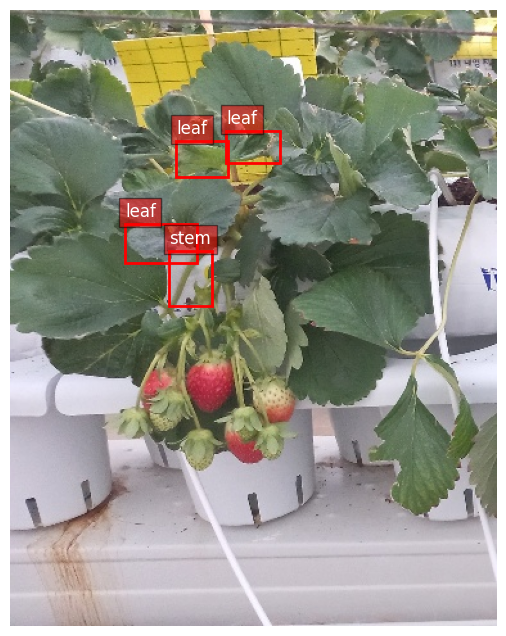

In [17]:
import cv2
import matplotlib.pyplot as plt

def visualize_yolo(image_path, label_path, classes: dict):
    # 이미지 읽기 (OpenCV는 BGR이므로 RGB로 변환)
    img = cv2.imread(image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape

    # 라벨 파일 읽기
    with open(label_path, 'r') as f:
        lines = f.readlines()

    plt.figure(figsize=(12, 8))
    plt.imshow(img)
    ax = plt.gca()

    for line in lines:
        parts = list(map(float, line.strip().split()))
        class_id = int(parts[0])
        x_center, y_center, width, height = parts[1:]

        # YOLO 좌표 역변환 (Normalized xywh -> pixel xy_min)
        x_min = (x_center - width / 2) * w
        y_min = (y_center - height / 2) * h
        box_w = width * w
        box_h = height * h

        # 사각형 그리기 (Matplotlib patch)
        rect = plt.Rectangle((x_min, y_min), box_w, box_h,
                             fill=False, color='red', linewidth=2)
        ax.add_patch(rect)

        # 텍스트 넣기
        label_text = classes[class_id] if classes else str(class_id)
        ax.text(x_min, y_min - 5, label_text,
                bbox=dict(facecolor='red', alpha=0.5), color='white', fontsize=12)

    plt.axis('off')
    plt.show()

# 사용
visualize_yolo(
    "/content/yolo_strawberry/images/val/딸기_설향_잎끝마름_88_009_221105071701.jpg",
    "/content/yolo_strawberry/labels/val/딸기_설향_잎끝마름_88_009_221105071701.txt",
    part_cat
)

In [25]:
data = {}
data['train'] = str(output_detection_path / "images" / "train")
data['val'] = str(output_detection_path / "images" / "val")
data['test'] = str(output_detection_path / "images" / "test")
data['nc'] = 2
data['names'] = list(part_cat.values())
with open(output_detection_path / "data.yaml", "w") as f:
    yaml.dump(data, f, default_flow_style=False)

In [26]:
!cat {output_detection_path / "data.yaml"}

names:
- leaf
- stem
nc: 2
test: /content/yolo_strawberry/images/test
train: /content/yolo_strawberry/images/train
val: /content/yolo_strawberry/images/val


In [30]:
model = YOLO("yolo11s.pt")

In [40]:
wandb.finish()
ultralytics.settings.update({"wandb": True})

In [33]:
results = model.train(
    data=output_detection_path / "data.yaml",
    epochs=100,
    imgsz=480,
    project="smartfarm-strawberry-detection",
    name="yolo11s",
    batch=-1,
    patience=10,
    optimizer='SGD',
    lr0=0.01,
    cache=True,
    amp=False,
    # resume=True,

    # Hyperparameter for high recall
    #cls=1.5,                # Higher class loss for aggresive detection
    # label_smoothing=0.1,    # Label smoothing to lower cost of misdetection
    warmup_epochs=3,        # For more stabilized warmup
)

Ultralytics 8.4.0 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (NVIDIA L4, 22693MiB)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=True, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_strawberry/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=480, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11s, nbs=64, nms=False, opset=None, optimize=False, optimizer=SGD, overlap_mask=True, patience=10, perspective=0.0, plo

Overriding model.yaml nc=80 with nc=2

                   from  n    params  module                                       arguments                     
  0                  -1  1       928  ultralytics.nn.modules.conv.Conv             [3, 32, 3, 2]                 
  1                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                
  2                  -1  1     26080  ultralytics.nn.modules.block.C3k2            [64, 128, 1, False, 0.25]     
  3                  -1  1    147712  ultralytics.nn.modules.conv.Conv             [128, 128, 3, 2]              
  4                  -1  1    103360  ultralytics.nn.modules.block.C3k2            [128, 256, 1, False, 0.25]    
  5                  -1  1    590336  ultralytics.nn.modules.conv.Conv             [256, 256, 3, 2]              
  6                  -1  1    346112  ultralytics.nn.modules.block.C3k2            [256, 256, 1, True]           
  7                  -1  1   1180672  ultralytics

wandb: WARNING Tried to log to step 100 that is less than the current step 101. Steps must be monotonically increasing, so this data will be ignored. See https://wandb.me/define-metric to log data out of order.


lr/pg0,████▇▇▇▇▇▆▆▆▆▅▅▅▅▅▅▄▄▄▄▄▄▄▃▃▃▃▃▃▃▃▂▂▁▁▁▁
lr/pg1,▃████▇▇▇▇▇▆▆▆▆▆▅▅▅▅▅▅▅▄▄▄▄▄▄▄▃▃▃▃▃▃▂▂▂▁▁
lr/pg2,▃███▇▇▇▇▇▇▇▇▆▆▆▆▆▆▅▅▅▅▅▄▄▄▃▃▃▃▃▃▂▂▂▂▂▁▁▁
metrics/mAP50(B),▁▃▃▃▄▅▅▅▆▆▆▆▇▇▇▇▇▇██████████████████████
metrics/mAP50-95(B),▁▂▃▃▄▅▅▆▆▆▇▇▇▇▇▇████████████████████████
metrics/precision(B),▁▂▂▃▅▆▆▆▇▇▇▇▇▇▇█████████████████████████
metrics/recall(B),▁▃▅▅▅▆▆▆▆▆▇▇▇▇▇▇██▇█████████████████████
model/GFLOPs,▁
model/parameters,▁
model/speed_PyTorch(ms),▁
+6,...


In [46]:
import gc
gc.collect()
import torch
torch.cuda.empty_cache()

In [37]:
# save_path = Path(results.save_dir) / "best.pt"
# print(save_path)
!cp /content/smartfarm-strawberry-detection/yolo11s/weights/best.pt /content/drive/MyDrive/bootcamp_proj/proj1/detection_11s_try1_best.pt

# Test the model

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 46392 (\N{HANGUL SYLLABLE DDAL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49444 (\N{HANGUL SYLLABLE SEOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54693 (\N{HANGUL SYLLABLE HYANG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


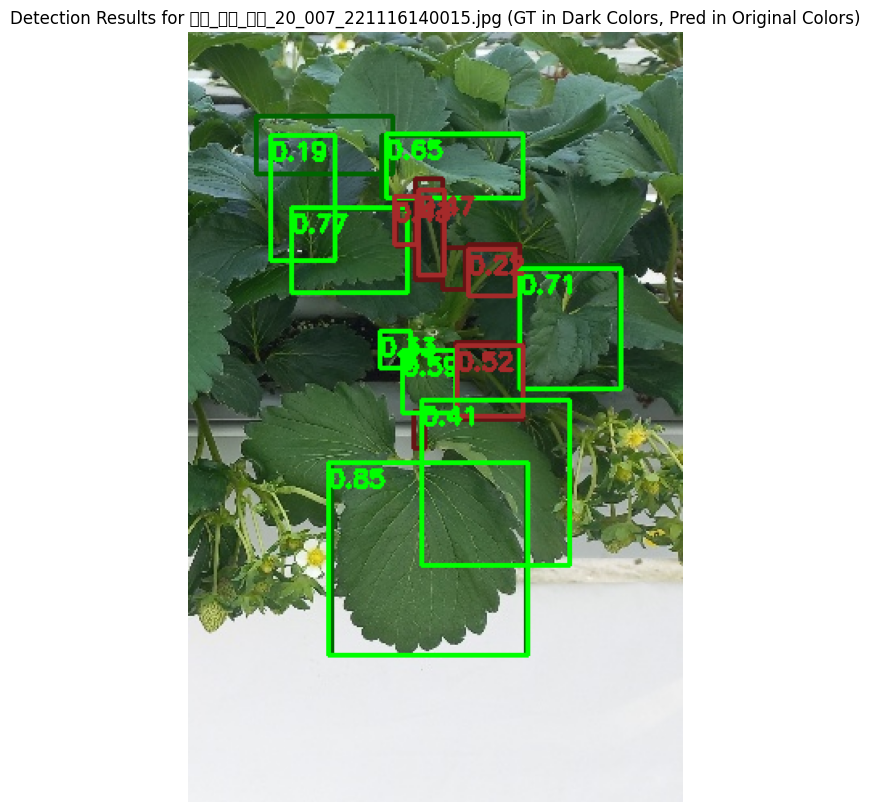

In [17]:
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO
from pathlib import Path

# Path to the trained model's best weights
model_path = Path("/content/drive/MyDrive/bootcamp_proj/proj1/detection_11s_try1_best.pt")

# Load the YOLO model
model = YOLO(model_path)

# Parameters for prediction and visualization
nth_img: int = 84 # Index of the image to visualize from the training set
conf: float = 0.1 # Confidence threshold for displaying model predictions
iou: float = 0.3 # IoU threshold for NMS in model predictions

# Define colors for predicted bounding boxes (as requested by the user)
pred_class_colors = {
    0: (0, 255, 0),    # Green for class 0 (leaf)
    1: (42, 42, 165)  # Brown for class 1 (stem) - BGR equivalent of (165, 42, 42) RGB
}

# Define colors for ground truth bounding boxes (as requested by the user)
gt_class_colors = {
    0: (0, 100, 0),    # Dark Green for class 0 (leaf)
    1: (20, 20, 100)   # Dark Brown for class 1 (stem)
}

# Get a sample image path from the train set (since pseudo-labels are generated for train)
sample_image_dir = output_detection_path / "images/train" # Use train directory
sample_label_dir = output_detection_path / "labels/train" # Use original labels directory for ground truth

# Ensure the directory exists and contains images
if not sample_image_dir.exists() or not any(sample_image_dir.iterdir()):
    print(f"Error: Train image directory not found or empty: {sample_image_dir}")
else:
    image_files = list(sample_image_dir.glob("*.jpg"))
    if len(image_files) == 0:
        print(f"Error: No JPEG images found in {sample_image_dir}")
    else:
        sample_image_path = image_files[nth_img % len(image_files)] # Use modulo to prevent out of bounds
        sample_gt_label_path = sample_label_dir / (sample_image_path.stem + ".txt")

        # Function to visualize predictions and ground truth
        def visualize_predictions_and_gt(image_path, model, pred_class_colors, gt_class_colors, ground_truth_label_path, class_names: dict, conf_threshold: float, iou_threshold: float):
            img = cv2.imread(str(image_path))
            if img is None:
                print(f"Error: Could not read image at {image_path}")
                return

            h, w, _ = img.shape
            display_img = img.copy() # Make a copy to draw on for display

            # 1. Draw Ground Truth Labels
            if ground_truth_label_path.exists():
                with open(ground_truth_label_path, 'r') as f:
                    for line in f:
                        parts = list(map(float, line.strip().split()))
                        if len(parts) == 5:
                            class_id_gt = int(parts[0])
                            x_center_gt, y_center_gt, width_gt, height_gt = parts[1:]

                            # Convert normalized YOLO format to pixel coordinates (xyxy)
                            x1_gt = int((x_center_gt - width_gt / 2) * w)
                            y1_gt = int((y_center_gt - height_gt / 2) * h)
                            x2_gt = int((x_center_gt + width_gt / 2) * w)
                            y2_gt = int((y_center_gt + height_gt / 2) * h)

                            # Use specified GT class colors
                            gt_color_for_class = gt_class_colors.get(class_id_gt, (0, 0, 0)) # Default to black if class_id is unexpected
                            cv2.rectangle(display_img, (x1_gt, y1_gt), (x2_gt, y2_gt), gt_color_for_class, 2)

                            # Display class name for ground truth
                            # label_text_gt = class_names.get(class_id_gt, str(class_id_gt))
                            # cv2.putText(display_img, label_text_gt, (x1_gt, y1_gt - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, gt_color_for_class, 2)
            else:
                print(f"Warning: Ground truth label file not found for {ground_truth_label_path.name}")

            # 2. Draw Model Predictions
            results = model.predict(source=img, save=False, verbose=False, conf=conf_threshold, iou=iou_threshold)

            for r in results:
                boxes = r.boxes
                for box in boxes:
                    try:
                        x1, y1, x2, y2 = map(int, box.xyxy[0])
                    except Exception as e:
                        print(f"Error parsing bounding box coordinates: {e}")
                        continue
                    class_id_pred = int(box.cls[0])
                    confidence = float(box.conf[0])

                    # Use specified prediction class colors
                    pred_color_for_class = pred_class_colors.get(class_id_pred, (0, 0, 255)) # Default red for unknown classes

                    # Draw rectangle for prediction
                    cv2.rectangle(display_img, (x1, y1), (x2, y2), pred_color_for_class, 2)
                    # Adjust y-position for prediction label to avoid overlap with GT label
                    label_text_pred = f"{confidence:.2f}"
                    cv2.putText(display_img, label_text_pred, (x1, y1 + 15), cv2.FONT_HERSHEY_SIMPLEX, 0.5, pred_color_for_class, 2)

            img_rgb = cv2.cvtColor(display_img, cv2.COLOR_BGR2RGB)

            plt.figure(figsize=(10, 10))
            plt.imshow(img_rgb)
            plt.axis('off')
            plt.title(f"Detection Results for {image_path.name} (GT in Dark Colors, Pred in Original Colors)")
            plt.show()

        # Call the visualization function with the sample image and its ground truth label path
        visualize_predictions_and_gt(
            sample_image_path,
            model,
            pred_class_colors, # Pass prediction colors
            gt_class_colors,   # Pass ground truth colors
            sample_gt_label_path,
            part_cat,
            conf,
            iou
        )

# Try2 Idea
----
- Use better model to pseudolabel

Pseudo-labelling

In [19]:
from ultralytics import YOLO
from pathlib import Path
import cv2
from tqdm.notebook import tqdm
import numpy as np # Needed for numpy operations with bounding boxes

# Define the path for pseudo-labels
output_train_pseudolabel_path = output_detection_path / "labels/train_pseudolabel"
output_train_pseudolabel_path.mkdir(parents=True, exist_ok=True)

# Define a confidence threshold for pseudo-labeling
# Only predictions with confidence above this threshold will be saved.
PSEUDO_CONF_THRESHOLD = 0.1

# Define an IoU threshold for deduplication
IOU_DEDUPLICATION_THRESHOLD = 0.7 # If IoU > this, assume it's the same object

# Batch size for inference
BATCH_SIZE = 32

# Helper function to calculate IoU for normalized (x_center, y_center, width, height) format
def calculate_iou_normalized(box1, box2):
    # box format: (x_center, y_center, width, height) normalized
    # Convert to (x1, y1, x2, y2)
    box1_x1, box1_y1, box1_x2, box1_y2 = box1[0] - box1[2]/2, box1[1] - box1[3]/2, box1[0] + box1[2]/2, box1[1] + box1[3]/2
    box2_x1, box2_y1, box2_x2, box2_y2 = box2[0] - box2[2]/2, box2[1] - box2[3]/2, box2[0] + box2[2]/2, box2[1] + box2[3]/2

    # determine the coordinates of the intersection rectangle
    x_left = max(box1_x1, box2_x1)
    y_top = max(box1_y1, box2_y1)
    x_right = min(box1_x2, box2_x2)
    y_bottom = min(box1_y2, box2_y2)

    if x_right < x_left or y_bottom < y_top:
        return 0.0

    # The intersection area
    intersection_area = (x_right - x_left) * (y_bottom - y_top)

    # The union area
    box1_area = (box1_x2 - box1_x1) * (box1_y2 - box1_y1)
    box2_area = (box2_x2 - box2_x1) * (box2_y2 - box2_y1)
    union_area = float(box1_area + box2_area - intersection_area)

    return intersection_area / union_area if union_area > 0 else 0.0

# Get a list of all image files in the training image directory
image_files = list(output_train_img_path.glob("*.jpg")) # Assuming images are .jpg

print(f"Generating pseudo-labels for {len(image_files)} images in batches of {BATCH_SIZE}...")

# Iterate through image files in batches
for i in tqdm(range(0, len(image_files), BATCH_SIZE), desc="Pseudo-labeling images"):
    batch_files = image_files[i : i + BATCH_SIZE]

    # Perform inference on the batch
    # Ultralytics accepts a list of file paths (as strings or Path objects)
    # verbose=False suppresses prediction output for cleaner logs
    results = model.predict(source=batch_files, verbose=False, conf=PSEUDO_CONF_THRESHOLD, iou=0.3)

    # Process each result in the batch
    for r in results:
        img_path = Path(r.path) # Get the original image path from the result object

        combined_labels_data = []

        # 1. Load Original Ground Truth Labels
        # This ensures that original labels (including stems) are preserved.
        original_label_path = output_train_label_path / (img_path.stem + ".txt")
        if original_label_path.exists():
            with open(original_label_path, 'r') as f:
                for line in f:
                    parts = list(map(float, line.strip().split()))
                    if len(parts) == 5: # Ensure it's a valid YOLO label line
                        class_id = int(parts[0])
                        bbox_normalized = parts[1:] # x_c, y_c, w, h
                        combined_labels_data.append([class_id] + bbox_normalized)
        # else:
            # print(f"Warning: Original label file not found for {img_path.name}. Proceeding with only pseudo-labels.")

        # 2. Add unique Pseudo-Labels, avoiding duplication with original labels
        boxes = r.boxes
        for box in boxes:
            class_id = int(box.cls[0])

            # Skip pseudo-labeling for stem (class 1)
            # This ensures we rely on the original labels for stems and do not add model predictions for them.
            if class_id == 1:
                continue

            # box.xywhn returns normalized x_center, y_center, width, height
            pseudo_bbox_normalized = box.xywhn[0].cpu().numpy() # Extract normalized bbox and convert to numpy array

            is_duplicate = False
            # Compare pseudo-label with all existing labels in combined_labels_data
            for existing_label in combined_labels_data:
                # Only compare bounding box part for IoU
                if calculate_iou_normalized(pseudo_bbox_normalized, existing_label[1:]) > IOU_DEDUPLICATION_THRESHOLD:
                    is_duplicate = True
                    break # Found a significant overlap, so it's a duplicate

            if not is_duplicate:
                combined_labels_data.append([class_id] + pseudo_bbox_normalized.tolist()) # Add if not a duplicate

        # Prepare content for the YOLO label file
        label_content_to_write = []
        for label_item in combined_labels_data:
            class_id = int(label_item[0])
            x_center, y_center, box_width, box_height = label_item[1:]
            label_content_to_write.append(f"{class_id} {x_center:.6f} {y_center:.6f} {box_width:.6f} {box_height:.6f}")

        # Construct the filename for the pseudo-label file
        label_filename = img_path.stem + ".txt"

        # Write the combined label content to the pseudo-label directory
        with open(output_train_pseudolabel_path / label_filename, "w") as f:
            f.write("\n".join(label_content_to_write))

print("Pseudo-labeling complete!")

Generating pseudo-labels for 15206 images in batches of 32...


Pseudo-labeling images:   0%|          | 0/476 [00:00<?, ?it/s]

Pseudo-labeling complete!


In [23]:
!mkdir -p /content/yolo_strawberry/pseudolabels/train
!mv /content/yolo_strawberry/labels/train_pseudolabel/* /content/yolo_strawberry/pseudolabels/train/

In [24]:
!mv /content/yolo_strawberry/labels /content/yolo_strawberry/orig_labels
!mv /content/yolo_strawberry/pseudolabels/ /content/yolo_strawberry/labels
!cp -r /content/yolo_strawberry/orig_labels/test/ /content/yolo_strawberry/labels/
!cp -r /content/yolo_strawberry/orig_labels/val/ /content/yolo_strawberry/labels/

## Visualize & Retrain

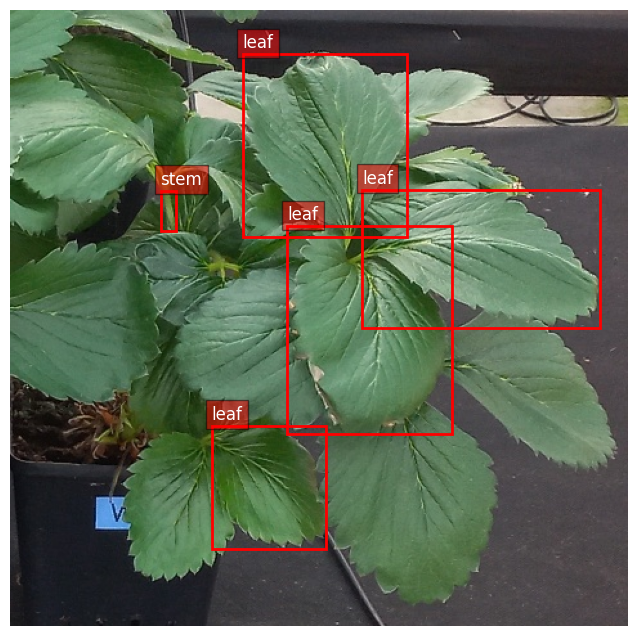

In [25]:
import cv2
import matplotlib.pyplot as plt

def visualize_yolo(image_path, label_path, classes: dict):
    # 이미지 읽기 (OpenCV는 BGR이므로 RGB로 변환)
    img = cv2.imread(image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape

    # 라벨 파일 읽기
    with open(label_path, 'r') as f:
        lines = f.readlines()

    plt.figure(figsize=(12, 8))
    plt.imshow(img)
    ax = plt.gca()

    for line in lines:
        parts = list(map(float, line.strip().split()))
        class_id = int(parts[0])
        x_center, y_center, width, height = parts[1:]

        # YOLO 좌표 역변환 (Normalized xywh -> pixel xy_min)
        x_min = (x_center - width / 2) * w
        y_min = (y_center - height / 2) * h
        box_w = width * w
        box_h = height * h

        # 사각형 그리기 (Matplotlib patch)
        rect = plt.Rectangle((x_min, y_min), box_w, box_h,
                             fill=False, color='red', linewidth=2)
        ax.add_patch(rect)

        # 텍스트 넣기
        label_text = classes[class_id] if classes else str(class_id)
        ax.text(x_min, y_min - 5, label_text,
                bbox=dict(facecolor='red', alpha=0.5), color='white', fontsize=12)

    plt.axis('off')
    plt.show()

# 사용
visualize_yolo(
    "/content/yolo_strawberry/images/train/딸기_설향_시들음병_07_021_220720062855.jpg",
    "/content/yolo_strawberry/labels/train/딸기_설향_시들음병_07_021_220720062855.txt",
    part_cat
)

In [26]:
from ultralytics import YOLO
import yaml

In [27]:
data = {}
data['train'] = str(output_detection_path / "images" / "train")
data['val'] = str(output_detection_path / "images" / "val")
data['test'] = str(output_detection_path / "images" / "test")
data['nc'] = 2
data['names'] = list(part_cat.values())
with open(output_detection_path / "data.yaml", "w") as f:
    yaml.dump(data, f, default_flow_style=False)

In [28]:
!cat {output_detection_path / "data.yaml"}

names:
- leaf
- stem
nc: 2
test: /content/yolo_strawberry/images/test
train: /content/yolo_strawberry/images/train
val: /content/yolo_strawberry/images/val


In [29]:
model = YOLO("yolo11s.pt")

In [30]:
wandb.finish()
ultralytics.settings.update({"wandb": True})

In [31]:
results = model.train(
    data=output_detection_path / "data.yaml",
    epochs=100,
    imgsz=480,
    project="smartfarm-strawberry-detection",
    name="yolo11s-pseudolabel",
    batch=32,
    # patience=10,
    optimizer='SGD',
    lr0=0.01,
    cache=True,
    # amp=False,
    # resume=True,

    # Hyperparameter for high recall
    #cls=1.5,                # Higher class loss for aggresive detection
    # label_smoothing=0.1,    # Label smoothing to lower cost of misdetection
    warmup_epochs=3,        # For more stabilized warmup
)

Ultralytics 8.4.2 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (NVIDIA L4, 22693MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=True, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_strawberry/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=480, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11s-pseudolabel, nbs=64, nms=False, opset=None, optimize=False, optimizer=SGD, overlap_mask=True, patience=100, perspect

Overriding model.yaml nc=80 with nc=2

                   from  n    params  module                                       arguments                     
  0                  -1  1       928  ultralytics.nn.modules.conv.Conv             [3, 32, 3, 2]                 
  1                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                
  2                  -1  1     26080  ultralytics.nn.modules.block.C3k2            [64, 128, 1, False, 0.25]     
  3                  -1  1    147712  ultralytics.nn.modules.conv.Conv             [128, 128, 3, 2]              
  4                  -1  1    103360  ultralytics.nn.modules.block.C3k2            [128, 256, 1, False, 0.25]    
  5                  -1  1    590336  ultralytics.nn.modules.conv.Conv             [256, 256, 3, 2]              
  6                  -1  1    346112  ultralytics.nn.modules.block.C3k2            [256, 256, 1, True]           
  7                  -1  1   1180672  ultralytics

lr/pg0,█▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
lr/pg1,████▇▇▇▇▇▇▇▆▆▆▆▅▅▄▄▄▄▄▄▃▃▃▃▃▃▃▂▂▂▂▂▁▁▁▁▁
lr/pg2,▃▆███▇▇▇▇▇▆▆▆▆▅▅▅▅▅▄▄▄▄▄▄▃▃▃▃▂▂▂▂▂▂▁▁▁▁▁
metrics/mAP50(B),▁▃▄▄▅▆▇▇▇▇▇▇▇███████████████████████████
metrics/mAP50-95(B),▁▄▄▄▅▅▅▆▆▇▇▇▇▇▇█████████████████████████
metrics/precision(B),▇█▁▂▃▄▄▄▄▄▄▄▄▄▄▄▄▄▄▅▅▄▅▅▅▅▅▅▅▅▅▅▅▅▅▅▅▅▅▅
metrics/recall(B),▁▅▆▆▆▇▇▇▇▇██████████████████████████████
model/GFLOPs,▁
model/parameters,▁
model/speed_PyTorch(ms),▁
+6,...


In [32]:
# save_path = Path(results.save_dir) / "best.pt"
# print(save_path)
!cp /content/smartfarm-strawberry-detection/yolo11s-pseudolabel/weights/last.pt /content/drive/MyDrive/bootcamp_proj/proj1/detection_11s_try2_last.pt

# Test the model

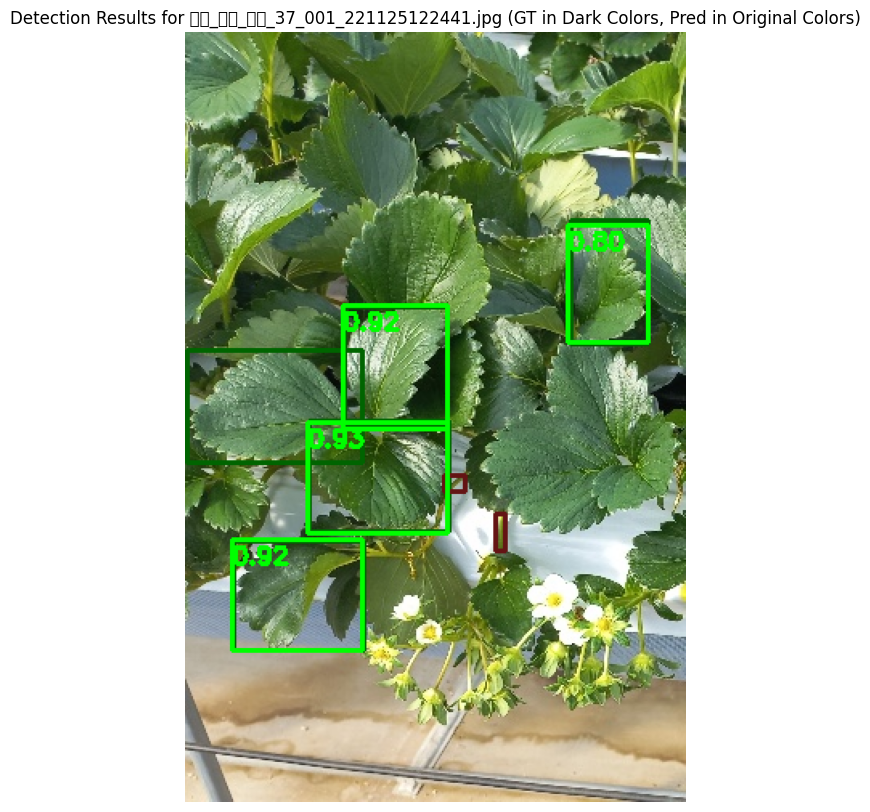

In [47]:
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO
from pathlib import Path

# Path to the trained model's best weights
model_path = Path("/content/drive/MyDrive/bootcamp_proj/proj1/detection_final.pt")

# Load the YOLO model
model = YOLO(model_path)

# Parameters for prediction and visualization
nth_img: int = 1972 # Index of the image to visualize from the training set
conf: float = 0.5 # Confidence threshold for displaying model predictions
iou: float = 0.5 # IoU threshold for NMS in model predictions

# Define colors for predicted bounding boxes (as requested by the user)
pred_class_colors = {
    0: (0, 255, 0),    # Green for class 0 (leaf)
    1: (42, 42, 165)  # Brown for class 1 (stem) - BGR equivalent of (165, 42, 42) RGB
}

# Define colors for ground truth bounding boxes (as requested by the user)
gt_class_colors = {
    0: (0, 100, 0),    # Dark Green for class 0 (leaf)
    1: (20, 20, 100)   # Dark Brown for class 1 (stem)
}

# Get a sample image path from the train set (since pseudo-labels are generated for train)
sample_image_dir = output_detection_path / "images/train" # Use train directory
sample_label_dir = output_detection_path / "labels/train" # Use original labels directory for ground truth

# Ensure the directory exists and contains images
if not sample_image_dir.exists() or not any(sample_image_dir.iterdir()):
    print(f"Error: Train image directory not found or empty: {sample_image_dir}")
else:
    image_files = list(sample_image_dir.glob("*.jpg"))
    if len(image_files) == 0:
        print(f"Error: No JPEG images found in {sample_image_dir}")
    else:
        sample_image_path = image_files[nth_img % len(image_files)] # Use modulo to prevent out of bounds
        sample_gt_label_path = sample_label_dir / (sample_image_path.stem + ".txt")

        # Function to visualize predictions and ground truth
        def visualize_predictions_and_gt(image_path, model, pred_class_colors, gt_class_colors, ground_truth_label_path, class_names: dict, conf_threshold: float, iou_threshold: float):
            img = cv2.imread(str(image_path))
            if img is None:
                print(f"Error: Could not read image at {image_path}")
                return

            h, w, _ = img.shape
            display_img = img.copy() # Make a copy to draw on for display

            # 1. Draw Ground Truth Labels
            if ground_truth_label_path.exists():
                with open(ground_truth_label_path, 'r') as f:
                    for line in f:
                        parts = list(map(float, line.strip().split()))
                        if len(parts) == 5:
                            class_id_gt = int(parts[0])
                            x_center_gt, y_center_gt, width_gt, height_gt = parts[1:]

                            # Convert normalized YOLO format to pixel coordinates (xyxy)
                            x1_gt = int((x_center_gt - width_gt / 2) * w)
                            y1_gt = int((y_center_gt - height_gt / 2) * h)
                            x2_gt = int((x_center_gt + width_gt / 2) * w)
                            y2_gt = int((y_center_gt + height_gt / 2) * h)

                            # Use specified GT class colors
                            gt_color_for_class = gt_class_colors.get(class_id_gt, (0, 0, 0)) # Default to black if class_id is unexpected
                            cv2.rectangle(display_img, (x1_gt, y1_gt), (x2_gt, y2_gt), gt_color_for_class, 2)

                            # Display class name for ground truth
                            # label_text_gt = class_names.get(class_id_gt, str(class_id_gt))
                            # cv2.putText(display_img, label_text_gt, (x1_gt, y1_gt - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, gt_color_for_class, 2)
            else:
                print(f"Warning: Ground truth label file not found for {ground_truth_label_path.name}")

            # 2. Draw Model Predictions
            results = model.predict(source=img, save=False, verbose=False, conf=conf_threshold, iou=iou_threshold)

            for r in results:
                boxes = r.boxes
                for box in boxes:
                    try:
                        x1, y1, x2, y2 = map(int, box.xyxy[0])
                    except Exception as e:
                        print(f"Error parsing bounding box coordinates: {e}")
                        continue
                    class_id_pred = int(box.cls[0])
                    confidence = float(box.conf[0])

                    # Use specified prediction class colors
                    pred_color_for_class = pred_class_colors.get(class_id_pred, (0, 0, 255)) # Default red for unknown classes

                    # Draw rectangle for prediction
                    cv2.rectangle(display_img, (x1, y1), (x2, y2), pred_color_for_class, 2)
                    # Adjust y-position for prediction label to avoid overlap with GT label
                    label_text_pred = f"{confidence:.2f}"
                    cv2.putText(display_img, label_text_pred, (x1, y1 + 15), cv2.FONT_HERSHEY_SIMPLEX, 0.5, pred_color_for_class, 2)

            img_rgb = cv2.cvtColor(display_img, cv2.COLOR_BGR2RGB)

            plt.figure(figsize=(10, 10))
            plt.imshow(img_rgb)
            plt.axis('off')
            plt.title(f"Detection Results for {image_path.name} (GT in Dark Colors, Pred in Original Colors)")
            plt.show()

        # Call the visualization function with the sample image and its ground truth label path
        visualize_predictions_and_gt(
            sample_image_path,
            model,
            pred_class_colors, # Pass prediction colors
            gt_class_colors,   # Pass ground truth colors
            sample_gt_label_path,
            part_cat,
            conf,
            iou
        )

In [43]:
!mv /content/drive/MyDrive/bootcamp_proj/proj1/detection_11s_try2_last.pt /content/drive/MyDrive/bootcamp_proj/proj1/detection_final.pt